# Klasifikasi Diagnosis Tumor Payudara dengan KNN (tanpa scikit-learn)

Alur notebook ini:
1. **EDA** - mengenal data + deteksi outlier (IQR & boxplot)
2. **Preprocessing** - bersihkan data, buang outlier, bagi 60/20/20, standardisasi
3. **Modeling** - KNN dibuat sendiri dengan NumPy
4. **Evaluasi** - pilih `k` via data validasi, lalu ukur akurasi, presisi, recall, F1
5. **Visualisasi** - PCA, batas keputusan, grafik metrik
6. **GUI Tkinter** - memprediksi data baru lewat jendela aplikasi


In [95]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 40)


## 1. Memuat Data

Dataset berisi pengukuran sel tumor. Kolom `diagnosis` adalah target: **M = ganas (malignant)**, **B = jinak (benign)**.


In [96]:
df = pd.read_csv('knn_dataset.csv')
print('Ukuran data:', df.shape)
df.head()


Ukuran data: (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


## 2. EDA (Exploratory Data Analysis)


In [97]:
print('Jumlah baris & kolom :', df.shape)
print('Nilai hilang         :', int(df.isna().sum().sum()))
print('Baris duplikat       :', int(df.duplicated().sum()))
print('Kolom kosong         :', df.columns[df.isna().all()].tolist())
print()
print('Jumlah data per diagnosis:')
print(df['diagnosis'].value_counts())


Jumlah baris & kolom : (569, 33)
Nilai hilang         : 569
Baris duplikat       : 0
Kolom kosong         : ['Unnamed: 32']

Jumlah data per diagnosis:
diagnosis
B    357
M    212
Name: count, dtype: int64


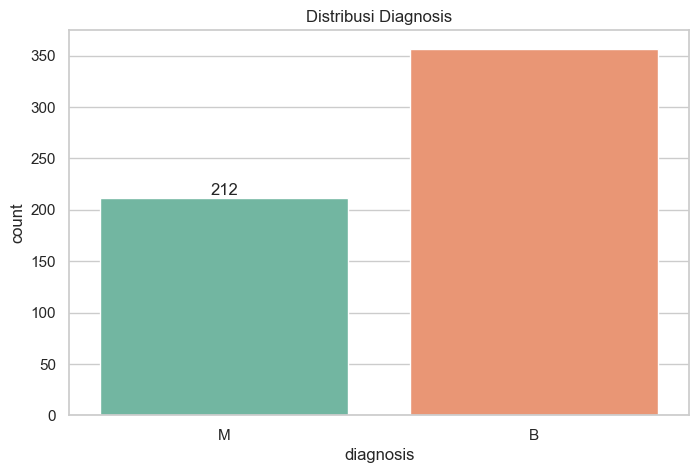

In [98]:
ax = sns.countplot(x='diagnosis', data=df, hue='diagnosis', palette='Set2', legend=False)
ax.bar_label(ax.containers[0])
ax.set_title('Distribusi Diagnosis')
plt.show()


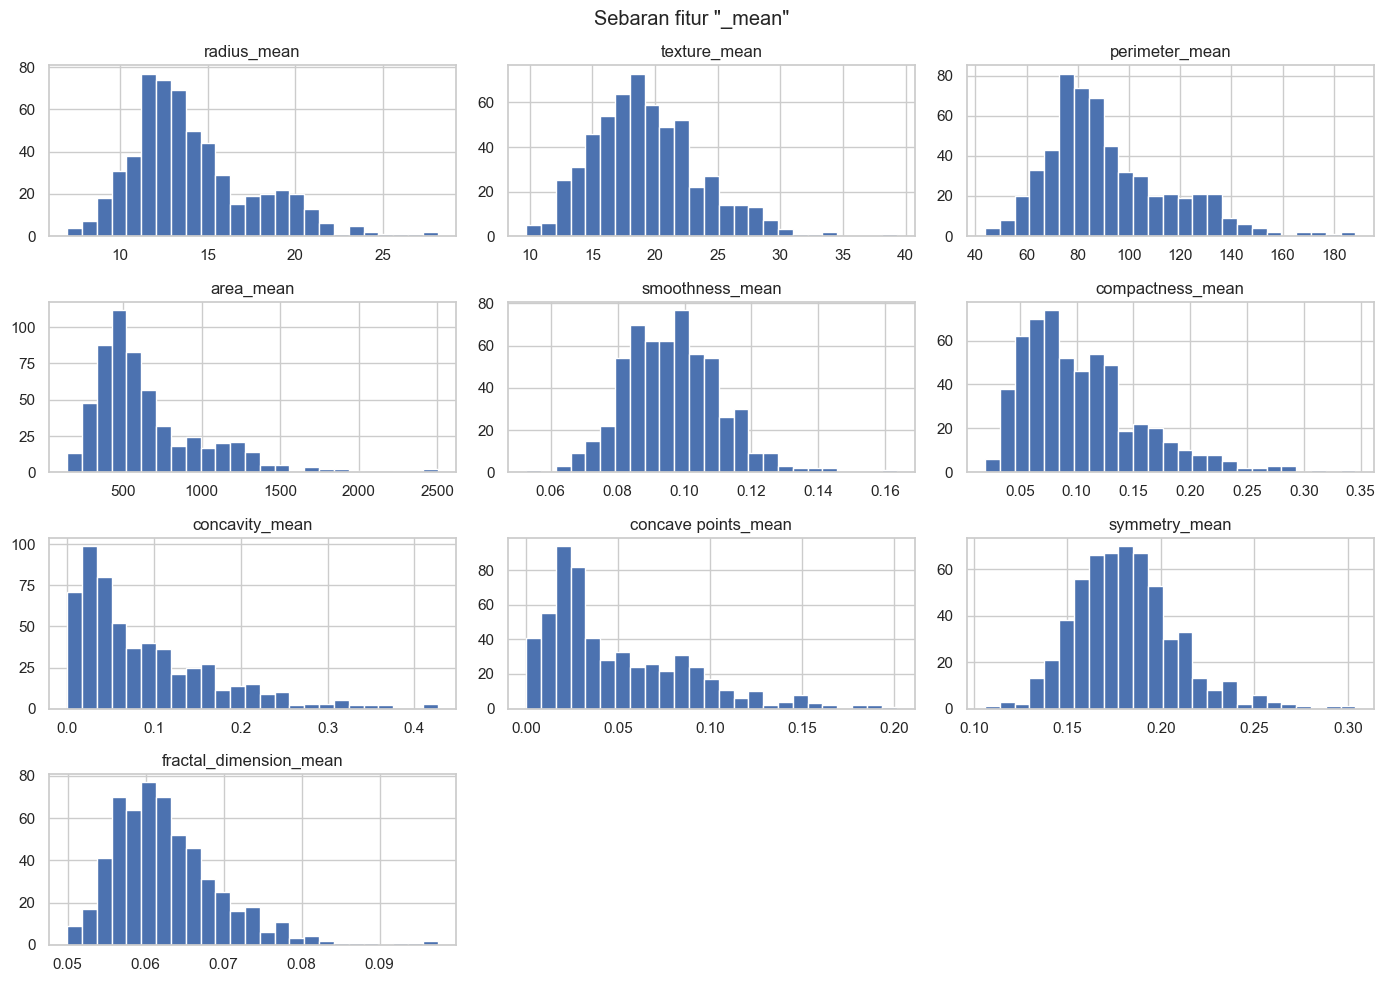

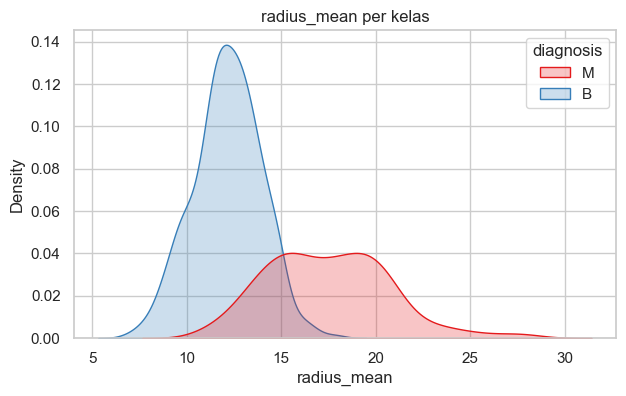

In [99]:
# Histogram semua fitur yang berakhiran '_mean'
fitur_mean = [c for c in df.columns if c.endswith('_mean')]
df[fitur_mean].hist(bins=25, figsize=(14, 10), color='#4C72B0', edgecolor='white')
plt.suptitle('Sebaran fitur "_mean"')
plt.tight_layout()
plt.show()

# Bandingkan satu fitur antara dua kelas
plt.figure(figsize=(7, 4))
sns.kdeplot(data=df, x='radius_mean', hue='diagnosis', fill=True, palette='Set1')
plt.title('radius_mean per kelas')
plt.show()


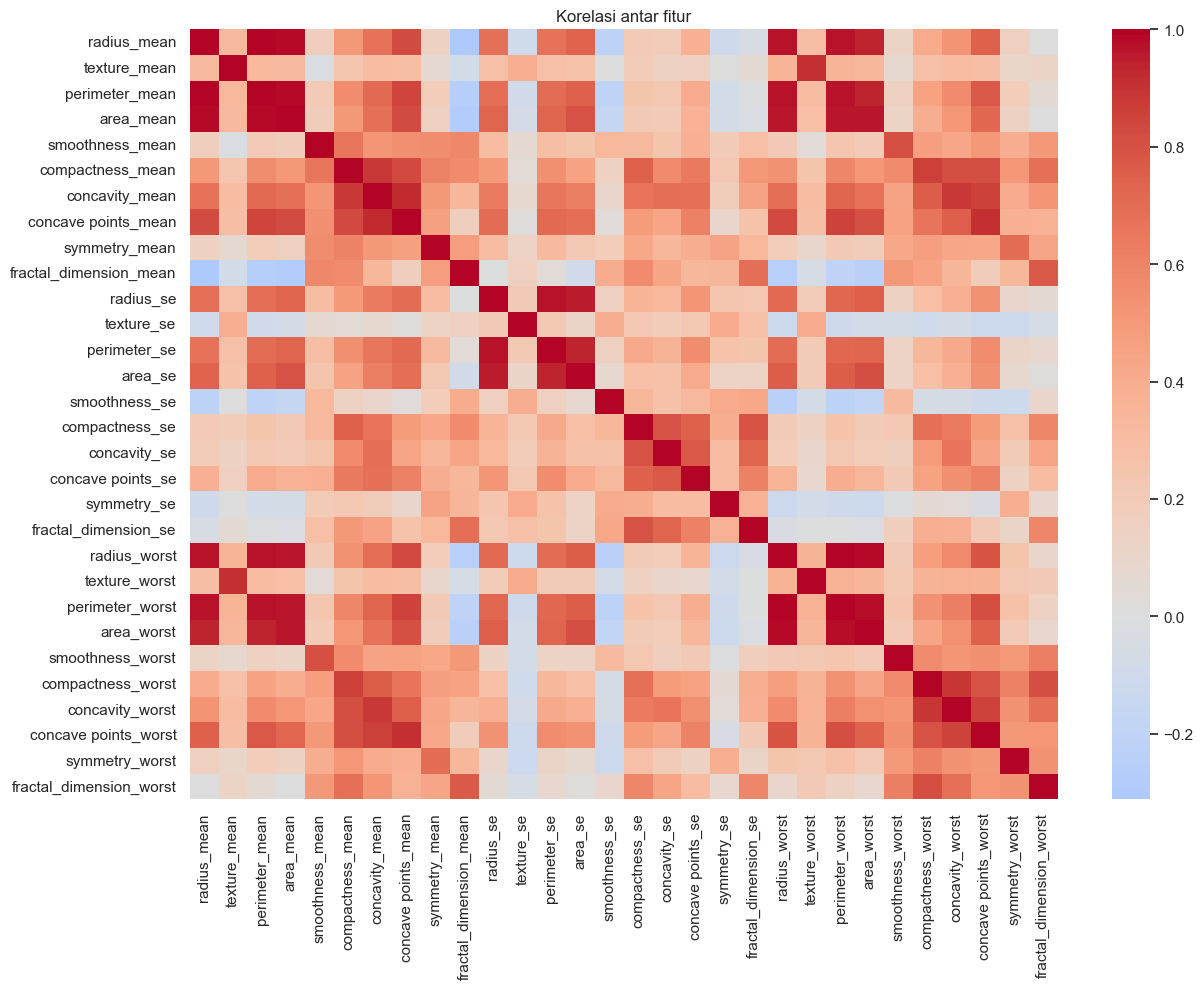

8 fitur paling berkorelasi dengan diagnosis:
concave points_worst    0.793566
perimeter_worst         0.782914
concave points_mean     0.776614
radius_worst            0.776454
perimeter_mean          0.742636
area_worst              0.733825
radius_mean             0.730029
area_mean               0.708984
Name: diagnosis, dtype: float64


In [100]:
# Ambil hanya kolom angka, buang kolom yang seluruhnya kosong
angka = df.drop(columns=['id']).select_dtypes('number').dropna(axis=1, how='all')

plt.figure(figsize=(14, 10))
sns.heatmap(angka.corr(), cmap='coolwarm', center=0)
plt.title('Korelasi antar fitur')
plt.show()

# Fitur yang paling berkorelasi dengan diagnosis (M=1, B=0)
angka['diagnosis'] = df['diagnosis'].map({'M': 1, 'B': 0})
print('8 fitur paling berkorelasi dengan diagnosis:')
print(angka.corr()['diagnosis'].drop('diagnosis').sort_values(ascending=False).head(8))


### Deteksi Outlier (IQR & Boxplot)

Metode **IQR (Interquartile Range)** menandai nilai yang berada di luar rentang:

`[Q1 - 1.5 x IQR, Q3 + 1.5 x IQR]` dengan `IQR = Q3 - Q1`.

Boxplot dipakai untuk melihat outlier secara visual (titik di luar garis whisker).


Jumlah outlier per fitur (hanya yang > 0):
area_se                    65
radius_se                  38
perimeter_se               38
area_worst                 35
smoothness_se              30
fractal_dimension_se       28
compactness_se             28
symmetry_se                27
area_mean                  25
fractal_dimension_worst    24
symmetry_worst             23
concavity_se               22
texture_se                 20
concave points_se          19
concavity_mean             18
radius_worst               17
compactness_worst          16
compactness_mean           16
fractal_dimension_mean     15
perimeter_worst            15
symmetry_mean              15
radius_mean                14
perimeter_mean             13
concavity_worst            12
concave points_mean        10
smoothness_worst            7
texture_mean                7
smoothness_mean             6
texture_worst               5
dtype: int64

Baris dengan minimal 1 outlier: 171 dari 569


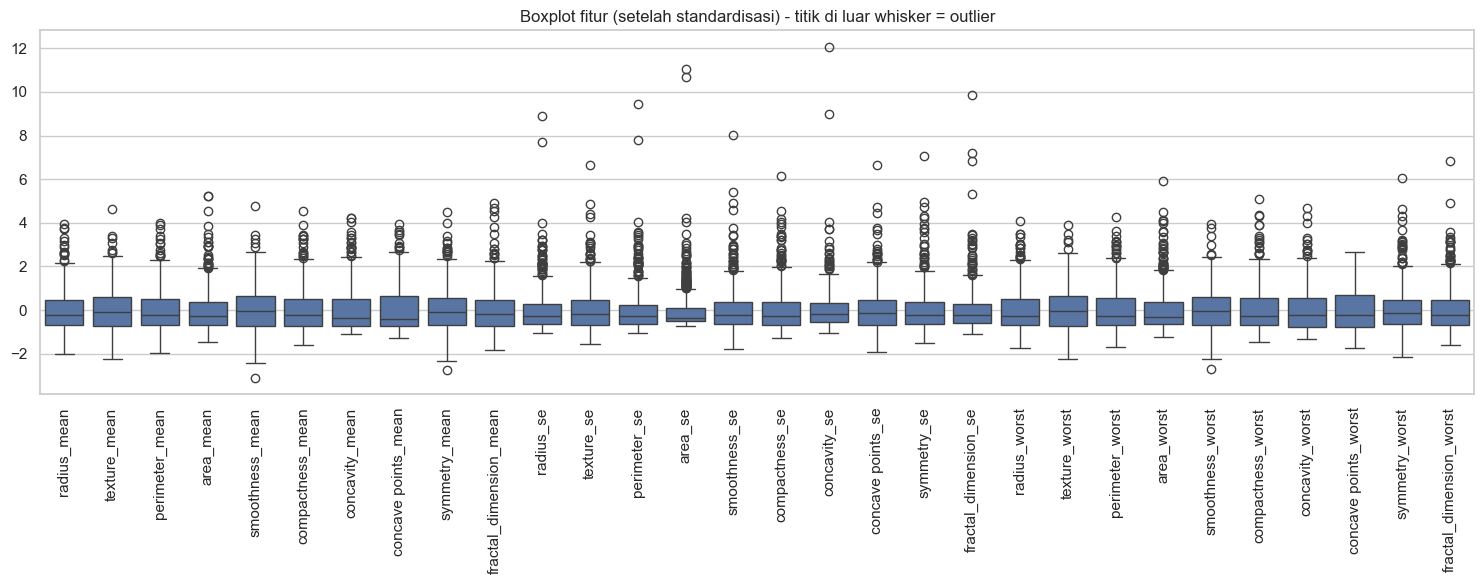

In [101]:
# Hitung batas IQR untuk setiap fitur angka
kolom_angka = df.drop(columns=['id']).select_dtypes('number').dropna(axis=1, how='all')

q1 = kolom_angka.quantile(0.25)
q3 = kolom_angka.quantile(0.75)
iqr = q3 - q1
batas_bawah = q1 - 1.5 * iqr
batas_atas = q3 + 1.5 * iqr

outlier = (kolom_angka < batas_bawah) | (kolom_angka > batas_atas)
print('Jumlah outlier per fitur (hanya yang > 0):')
print(outlier.sum()[outlier.sum() > 0].sort_values(ascending=False))
print()
print('Baris dengan minimal 1 outlier:', int(outlier.any(axis=1).sum()), 'dari', len(kolom_angka))

# Boxplot semua fitur. Distandardisasi dulu agar skalanya sebanding.
kolom_standar = (kolom_angka - kolom_angka.mean()) / kolom_angka.std()
plt.figure(figsize=(15, 6))
sns.boxplot(data=kolom_standar, color='#4C72B0')
plt.xticks(rotation=90)
plt.title('Boxplot fitur (setelah standardisasi) - titik di luar whisker = outlier')
plt.tight_layout()
plt.show()


**Catatan penting dari EDA**
- File CSV punya satu kolom kosong (`Unnamed: 32`) karena koma berlebih di akhir baris -> harus dibuang.
- Data cukup bersih: tidak ada nilai hilang selain kolom kosong itu, dan tidak ada duplikat.
- Kelas tidak seimbang (B lebih banyak dari M), jadi jangan hanya melihat akurasi.
- Ukuran tiap fitur berbeda jauh (`area_mean` ribuan, `smoothness_mean` di bawah 1), sehingga **standardisasi wajib** untuk KNN.
- Terdapat outlier pada beberapa fitur; akan ditangani dengan metode IQR pada tahap preprocessing.


## 3. Preprocessing


In [102]:
# 1) buang kolom id dan kolom yang seluruhnya kosong
data = df.drop(columns=['id']).dropna(axis=1, how='all')

# 2) buang baris duplikat
data = data.drop_duplicates().reset_index(drop=True)

# 3) ubah target jadi angka: M (ganas) = 1, B (jinak) = 0
data['diagnosis'] = data['diagnosis'].map({'M': 1, 'B': 0})

print('Ukuran data bersih:', data.shape)
data.head()


Ukuran data bersih: (569, 31)


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


outlier pada kolom radius_mean : 14
outlier pada kolom texture_mean : 7
outlier pada kolom perimeter_mean : 13
outlier pada kolom area_mean : 25
outlier pada kolom smoothness_mean : 6
outlier pada kolom compactness_mean : 16
outlier pada kolom concavity_mean : 18
outlier pada kolom concave points_mean : 10
outlier pada kolom symmetry_mean : 15
outlier pada kolom fractal_dimension_mean : 15
outlier pada kolom radius_se : 38
outlier pada kolom texture_se : 20
outlier pada kolom perimeter_se : 38
outlier pada kolom area_se : 65
outlier pada kolom smoothness_se : 30
outlier pada kolom compactness_se : 28
outlier pada kolom concavity_se : 22
outlier pada kolom concave points_se : 19
outlier pada kolom symmetry_se : 27
outlier pada kolom fractal_dimension_se : 28
outlier pada kolom radius_worst : 17
outlier pada kolom texture_worst : 5
outlier pada kolom perimeter_worst : 15
outlier pada kolom area_worst : 35
outlier pada kolom smoothness_worst : 7
outlier pada kolom compactness_worst : 16
o

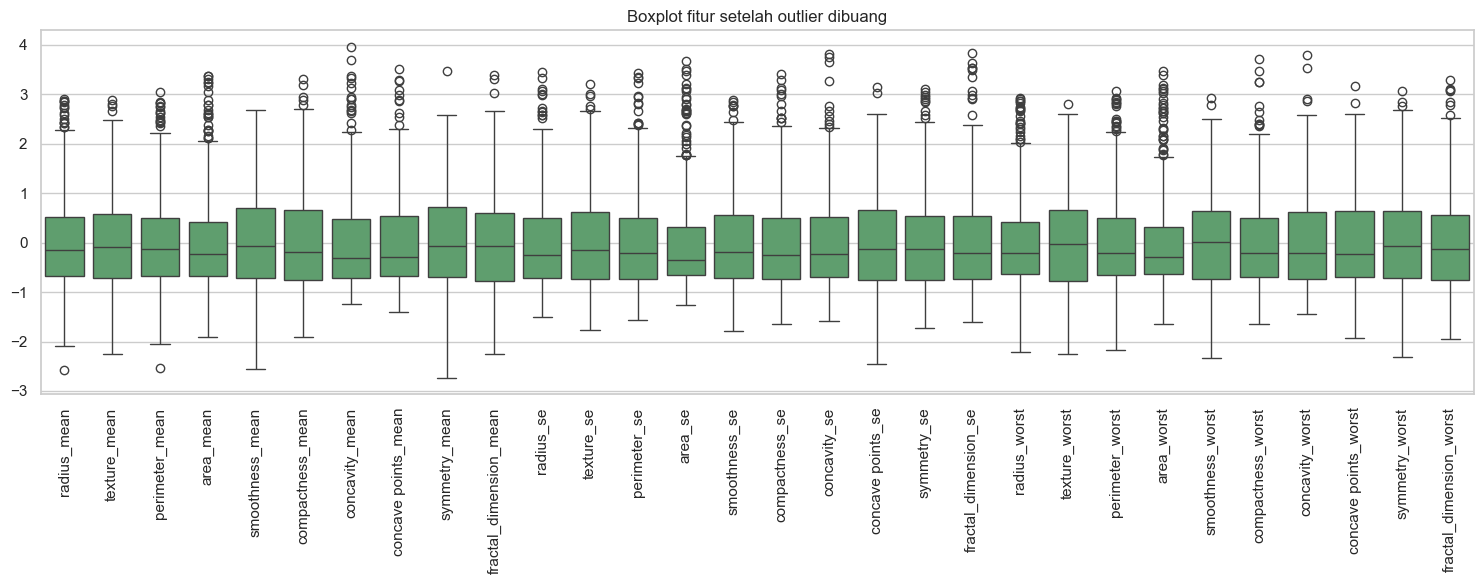

In [103]:
# Buang baris yang jadi outlier (metode IQR) di salah satu fitur
kolom_fitur = [c for c in data.columns if c != 'diagnosis']

buang = pd.Series(False, index=data.index)
for kolom in kolom_fitur:
    Q1 = data[kolom].quantile(0.25)
    Q3 = data[kolom].quantile(0.75)
    IQR = Q3 - Q1
    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR
    outlier = (data[kolom] < batas_bawah) | (data[kolom] > batas_atas)
    print(f'outlier pada kolom {kolom} : {int(outlier.sum())}')
    buang |= outlier

print('Total baris dengan outlier :', int(buang.sum()), 'dari', len(data))
data = data[~buang].reset_index(drop=True)
print('Jumlah baris setelah dibuang:', len(data))

# Boxplot setelah outlier dibuang
kolom_standar = (data[kolom_fitur] - data[kolom_fitur].mean()) / data[kolom_fitur].std()
plt.figure(figsize=(15, 6))
sns.boxplot(data=kolom_standar, color='#55A868')
plt.xticks(rotation=90)
plt.title('Boxplot fitur setelah outlier dibuang')
plt.tight_layout()
plt.show()


In [104]:
def split_data(X, y, train_size=0.6, val_size=0.2, random_state=56):
    """Bagi data jadi latih / validasi / uji (60% / 20% / 20%)."""
    np.random.seed(random_state)
    idx = np.random.permutation(len(X))
    batas_latih = int(train_size * len(X))
    batas_val = int((train_size + val_size) * len(X))

    X_train, X_val, X_test = X[idx[:batas_latih]], X[idx[batas_latih:batas_val]], X[idx[batas_val:]]
    y_train, y_val, y_test = y[idx[:batas_latih]], y[idx[batas_latih:batas_val]], y[idx[batas_val:]]
    return X_train, X_val, X_test, y_train, y_val, y_test


# Pisahkan fitur (X) dan target (y)
fitur = [c for c in data.columns if c != 'diagnosis']
X = data[fitur].to_numpy(float)
y = data['diagnosis'].to_numpy(int)

X_train, X_val, X_test, y_train, y_val, y_test = split_data(X, y)
print('Data latih    :', X_train.shape)
print('Data validasi :', X_val.shape)
print('Data uji      :', X_test.shape)

# Standardisasi z-score: (x - rata-rata) / simpangan baku.
# Rata-rata & simpangan dihitung dari data latih saja (agar tidak bocor ke data lain).
rerata = X_train.mean(axis=0)
simpangan = X_train.std(axis=0)
X_train_scaled = (X_train - rerata) / simpangan
X_val_scaled = (X_val - rerata) / simpangan
X_test_scaled = (X_test - rerata) / simpangan


Data latih    : (238, 30)
Data validasi : (80, 30)
Data uji      : (80, 30)


## 4. Modeling: KNN dari Nol

Cara kerja KNN:
1. Hitung jarak (Euclidean) data baru ke **semua** data latih.
2. Ambil `k` data yang jaraknya paling dekat.
3. Pilih kelas yang paling banyak muncul di antara mereka.


In [105]:
def knn_predict(X_train, y_train, X_test, k):
    """Tebak kelas X_test memakai KNN (jarak Euclidean + suara terbanyak)."""
    hasil = []
    for x in X_test:
        jarak = np.sqrt(((X_train - x) ** 2).sum(axis=1))  # jarak ke semua data latih
        tetangga = y_train[np.argsort(jarak)[:k]]          # k label terdekat
        hasil.append(np.bincount(tetangga).argmax())       # kelas terbanyak
    return np.array(hasil)


# Contoh cepat dengan k = 5
contoh_prediksi = knn_predict(X_train_scaled, y_train, X_test_scaled[:10], k=5)
print('Prediksi 10 data :', contoh_prediksi)
print('Label sebenarnya :', y_test[:10])


Prediksi 10 data : [0 0 0 0 1 0 0 1 0 0]
Label sebenarnya : [0 0 0 0 1 1 0 1 0 0]


## 5. Evaluasi


In [106]:
def hitung_akurasi(y_true, y_pred):
    """Akurasi = proporsi prediksi yang benar."""
    return float((y_true == y_pred).mean())


def evaluasi(y_true, y_pred):
    """Kembalikan akurasi, presisi, recall, F1, dan confusion matrix (kelas 1 = M)."""
    tp = int(((y_true == 1) & (y_pred == 1)).sum())
    tn = int(((y_true == 0) & (y_pred == 0)).sum())
    fp = int(((y_true == 0) & (y_pred == 1)).sum())
    fn = int(((y_true == 1) & (y_pred == 0)).sum())

    akurasi = (tp + tn) / len(y_true)
    presisi = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * presisi * recall / (presisi + recall) if presisi + recall else 0.0
    cm = np.array([[tn, fp], [fn, tp]])
    return akurasi, presisi, recall, f1, cm


Akurasi data validasi per k:
  k= 1 -> 0.9750
  k= 2 -> 0.9750
  k= 3 -> 0.9875
  k= 4 -> 0.9875
  k= 5 -> 0.9750
  k= 6 -> 0.9875
  k= 7 -> 0.9875
  k= 8 -> 0.9875
  k= 9 -> 0.9750
  k=10 -> 0.9875
  k=11 -> 0.9750
  k=12 -> 0.9750
  k=13 -> 0.9750
  k=14 -> 0.9750
  k=15 -> 0.9750
  k=16 -> 0.9750
  k=17 -> 0.9750
  k=18 -> 0.9750
  k=19 -> 0.9750
  k=20 -> 0.9750
k terbaik: 3 (akurasi validasi = 0.9875)


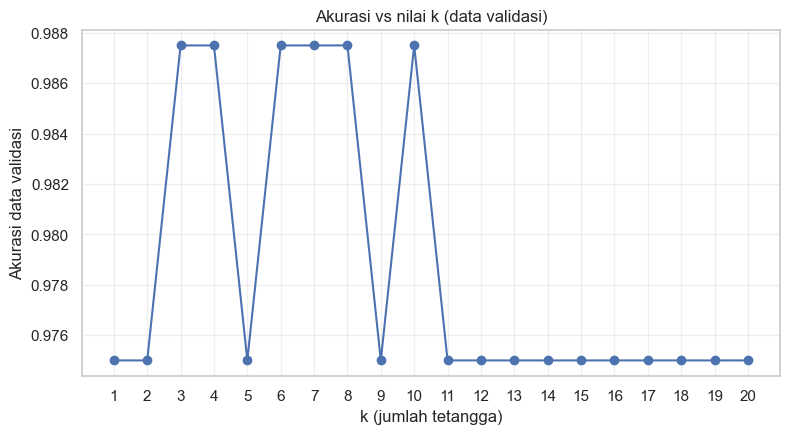

In [107]:
# Coba berbagai nilai k, pilih yang akurasinya terbaik di data VALIDASI
daftar_k = list(range(1, 21))
akurasi_val = [hitung_akurasi(y_val, knn_predict(X_train_scaled, y_train, X_val_scaled, k))
               for k in daftar_k]
k_terbaik = daftar_k[int(np.argmax(akurasi_val))]

print('Akurasi data validasi per k:')
for k, a in zip(daftar_k, akurasi_val):
    print(f'  k={k:2d} -> {a:.4f}')
print(f'k terbaik: {k_terbaik} (akurasi validasi = {max(akurasi_val):.4f})')

plt.figure(figsize=(9, 4.5))
plt.plot(daftar_k, akurasi_val, marker='o')
plt.xticks(daftar_k)
plt.xlabel('k (jumlah tetangga)')
plt.ylabel('Akurasi data validasi')
plt.title('Akurasi vs nilai k (data validasi)')
plt.grid(alpha=0.3)
plt.show()


Model final: KNN dengan k = 3
Akurasi  : 0.9500
Presisi  : 0.9286
Recall   : 0.8125
F1-Score : 0.8667


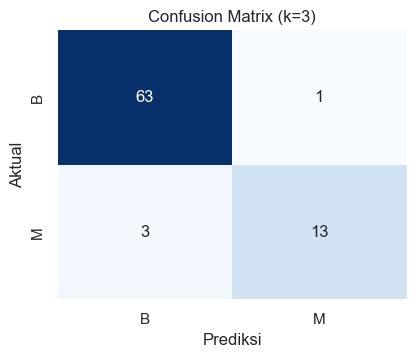

In [108]:
y_pred_final = knn_predict(X_train_scaled, y_train, X_test_scaled, k_terbaik)
akurasi_final, presisi_final, recall_final, f1_final, cm_final = evaluasi(y_test, y_pred_final)

print(f'Model final: KNN dengan k = {k_terbaik}')
print(f'Akurasi  : {akurasi_final:.4f}')
print(f'Presisi  : {presisi_final:.4f}')
print(f'Recall   : {recall_final:.4f}')
print(f'F1-Score : {f1_final:.4f}')

plt.figure(figsize=(4.5, 3.5))
sns.heatmap(cm_final, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['B', 'M'], yticklabels=['B', 'M'])
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.title(f'Confusion Matrix (k={k_terbaik})')
plt.show()


## 6. Visualisasi Hasil Modeling


PC1 + PC2 menjelaskan 60.7% variansi data
Salah klasifikasi: 10 dari 398 data


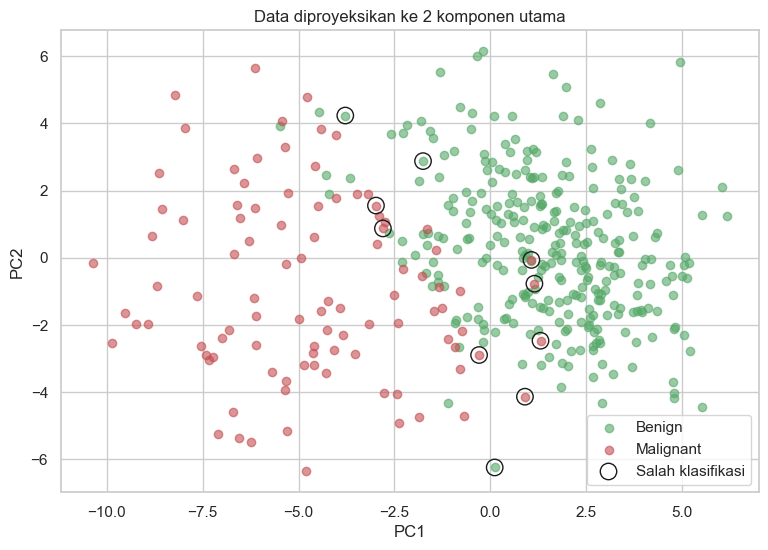

In [109]:
def pca_2d(X):
    """Proyeksikan data ke 2 komponen utama memakai SVD."""
    X_center = X - X.mean(axis=0)
    _, S, Vt = np.linalg.svd(X_center, full_matrices=False)
    rasio = S ** 2 / (S ** 2).sum()  # porsi variansi tiap komponen
    return X_center @ Vt[:2].T, rasio[:2]


X_scaled = (X - rerata) / simpangan          # semua data, memakai ukuran dari data latih
X_pca, rasio = pca_2d(X_scaled)
salah = knn_predict(X_train_scaled, y_train, X_scaled, k_terbaik) != y

print(f'PC1 + PC2 menjelaskan {rasio.sum() * 100:.1f}% variansi data')
print(f'Salah klasifikasi: {int(salah.sum())} dari {len(y)} data')

plt.figure(figsize=(9, 6))
plt.scatter(X_pca[y == 0, 0], X_pca[y == 0, 1], c='#55A868', alpha=0.6, label='Benign')
plt.scatter(X_pca[y == 1, 0], X_pca[y == 1, 1], c='#C44E52', alpha=0.6, label='Malignant')
plt.scatter(X_pca[salah, 0], X_pca[salah, 1], facecolors='none', edgecolors='k',
            s=140, label='Salah klasifikasi')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Data diproyeksikan ke 2 komponen utama')
plt.legend()
plt.show()


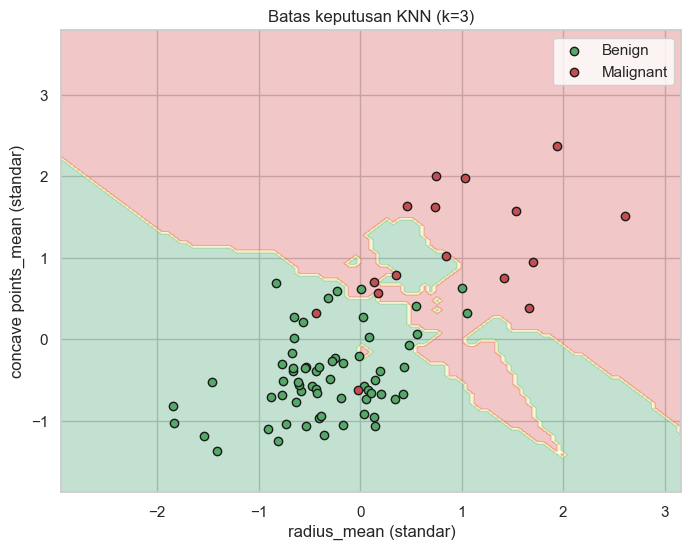

Akurasi 2 fitur  : 0.9000
Akurasi 30 fitur : 0.9500


In [110]:
# Latih KNN dengan 2 fitur paling berpengaruh, lalu gambar batas keputusannya
ia, ib = fitur.index('radius_mean'), fitur.index('concave points_mean')
X2_train, X2_test = X_train_scaled[:, [ia, ib]], X_test_scaled[:, [ia, ib]]

xx, yy = np.meshgrid(np.linspace(X2_train[:, 0].min() - 0.5, X2_train[:, 0].max() + 0.5, 100),
                     np.linspace(X2_train[:, 1].min() - 0.5, X2_train[:, 1].max() + 0.5, 100))
zz = knn_predict(X2_train, y_train, np.c_[xx.ravel(), yy.ravel()], k_terbaik).reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, zz, alpha=0.25, cmap='RdYlGn_r')
plt.scatter(X2_test[y_test == 0, 0], X2_test[y_test == 0, 1], c='#55A868', edgecolors='k', label='Benign')
plt.scatter(X2_test[y_test == 1, 0], X2_test[y_test == 1, 1], c='#C44E52', edgecolors='k', label='Malignant')
plt.xlabel('radius_mean (standar)')
plt.ylabel('concave points_mean (standar)')
plt.title(f'Batas keputusan KNN (k={k_terbaik})')
plt.legend()
plt.show()

akurasi_2_fitur = hitung_akurasi(y_test, knn_predict(X2_train, y_train, X2_test, k_terbaik))
print(f'Akurasi 2 fitur  : {akurasi_2_fitur:.4f}')
print(f'Akurasi {len(fitur)} fitur : {akurasi_final:.4f}')


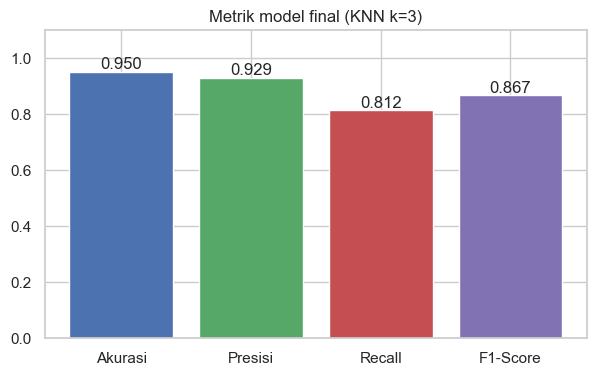

In [111]:
nama_metrik = ['Akurasi', 'Presisi', 'Recall', 'F1-Score']
nilai_metrik = [akurasi_final, presisi_final, recall_final, f1_final]

plt.figure(figsize=(7, 4))
batang = plt.bar(nama_metrik, nilai_metrik, color=['#4C72B0', '#55A868', '#C44E52', '#8172B3'])
plt.bar_label(batang, fmt='%.3f')
plt.ylim(0, 1.1)
plt.title(f'Metrik model final (KNN k={k_terbaik})')
plt.show()


## 7. GUI Prediksi dengan Tkinter

Jalankan cell di bawah, lalu:
1. Isi 30 kolom fitur (pakai **nilai asli**, bukan yang sudah distandardisasi), **atau** klik `Contoh Benign` / `Contoh Malignant` untuk mengisi otomatis.
2. Klik `Prediksi` untuk melihat hasil.
3. Klik `Reset` untuk mengosongkan form.

Jendela harus ditutup dulu sebelum notebook bisa lanjut (karena memakai `mainloop`).


In [112]:
import tkinter as tk
from tkinter import messagebox


def buat_aplikasi():
    akar = tk.Tk()
    akar.title('Prediksi Tumor Payudara - KNN')
    akar.geometry('820x620')
    akar.resizable(False, False)

    tk.Label(akar, text='Prediksi Diagnosis Tumor Payudara (KNN)',
             font=('Segoe UI', 14, 'bold')).pack(pady=(12, 2))
    tk.Label(akar, text=f'k = {k_terbaik}   |   akurasi data uji = {akurasi_final:.4f}').pack()

    # Form input: satu kolom untuk label, satu kolom untuk kotak isian
    form = tk.Frame(akar)
    form.pack(padx=15, pady=10)
    entri = []
    for i, nama_fitur in enumerate(fitur):
        baris, kolom = i % 15, (i // 15) * 2
        tk.Label(form, text=nama_fitur, width=22, anchor='w').grid(row=baris, column=kolom, sticky='w')
        kotak = tk.Entry(form, width=14)
        kotak.grid(row=baris, column=kolom + 1, padx=(0, 18))
        entri.append(kotak)

    pesan = tk.Label(akar, text='Belum ada prediksi.', font=('Segoe UI', 13, 'bold'))
    pesan.pack(pady=12)

    def prediksi():
        """Baca isi form, standardisasi, lalu prediksi."""
        try:
            nilai = [float(kotak.get()) for kotak in entri]
        except ValueError:
            messagebox.showerror('Input salah', 'Semua kolom harus diisi angka.')
            return
        x_scaled = (np.array(nilai) - rerata) / simpangan
        kelas = knn_predict(X_train_scaled, y_train, x_scaled.reshape(1, -1), k_terbaik)[0]
        nama_kelas = ['Benign (Jinak)', 'Malignant (Ganas)'][kelas]
        pesan.config(text=f'Hasil: {nama_kelas}', fg='#C44E52' if kelas == 1 else '#55A868')

    def isi_contoh(kelas, teks):
        """Isi form dengan satu contoh data uji."""
        for kotak, nilai in zip(entri, X_test[y_test == kelas][0]):
            kotak.delete(0, tk.END)
            kotak.insert(0, f'{nilai:.5f}')
        pesan.config(text=teks, fg='black')

    def kosongkan():
        for kotak in entri:
            kotak.delete(0, tk.END)
        pesan.config(text='Belum ada prediksi.', fg='black')

    tombol = tk.Frame(akar)
    tombol.pack()
    tk.Button(tombol, text='Prediksi', width=14, bg='#4C72B0', fg='white',
              command=prediksi).grid(row=0, column=0, padx=4)
    tk.Button(tombol, text='Contoh Benign', width=14,
              command=lambda: isi_contoh(0, 'Contoh Benign terisi.')).grid(row=0, column=1, padx=4)
    tk.Button(tombol, text='Contoh Malignant', width=14,
              command=lambda: isi_contoh(1, 'Contoh Malignant terisi.')).grid(row=0, column=2, padx=4)
    tk.Button(tombol, text='Reset', width=10,
              command=kosongkan).grid(row=0, column=3, padx=4)

    return akar


buat_aplikasi().mainloop()


## Ringkasan

| Tahap | Isi |
| --- | --- |
| EDA | Cek ukuran data, nilai hilang, sebaran kelas, histogram, korelasi, deteksi outlier (IQR + boxplot) |
| Preprocessing | Buang kolom kosong, encode target, buang outlier, bagi 60/20/20, standardisasi z-score |
| Modeling | `knn_predict()` - jarak Euclidean + suara terbanyak |
| Evaluasi | Pilih `k` via data validasi, lalu ukur metrik di data uji (akurasi, presisi, recall, F1, confusion matrix) |
| Visualisasi | PCA 2D, batas keputusan, grafik metrik |
| Aplikasi | GUI Tkinter untuk prediksi data baru |

Poin penting:
- Data dibagi 60% latih, 20% validasi, 20% uji memakai fungsi `split_data()`.
- Standardisasi dihitung dari data latih saja, lalu dipakai untuk data validasi & uji (mencegah kebocoran data).
- Semua rumus (jarak, metrik, IQR) ditulis manual dengan NumPy tanpa scikit-learn.
